In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
results_root = Path("results")

csv_paths = sorted(results_root.rglob("2_consecutive_rows_report.csv"))

if len(csv_paths) == 0:
    raise FileNotFoundError(
        "No files named '2_consecutive_rows_report.csv' were found under the 'results' folder."
    )

dfs = []
for p in csv_paths:
    tmp = pd.read_csv(p).copy()

    # infer subject folder name, e.g. BA1
    # path example: results/BA1/2_consecutive_rows_report.csv
    subject_id = None
    for part in p.parts:
        if str(part).upper().startswith("BA"):
            subject_id = part
            break

    tmp["subject_id"] = subject_id if subject_id is not None else p.parent.name
    tmp["source_file"] = str(p)
    dfs.append(tmp)

merged_reports = pd.concat(dfs, ignore_index=True)

print("Merged shape:", merged_reports.shape)
print("Number of source files:", len(csv_paths))
print("Subjects found:", merged_reports["subject_id"].nunique())
print(merged_reports.head())


Merged shape: (7730, 7)
Number of source files: 84
Subjects found: 84
                task_name  total_rows  kept_rows  discarded_rows  \
0           baseline_talk        1722       1722               0   
1  emotional_instructions         395        395               0   
2               eyesclose        2534       2534               0   
3                eyesopen        2571       2571               0   
4   frontal1_memorization        2359       2359               0   

   discarded_percent subject_id                                source_file  
0                0.0        BA1  results/BA1/2_consecutive_rows_report.csv  
1                0.0        BA1  results/BA1/2_consecutive_rows_report.csv  
2                0.0        BA1  results/BA1/2_consecutive_rows_report.csv  
3                0.0        BA1  results/BA1/2_consecutive_rows_report.csv  
4                0.0        BA1  results/BA1/2_consecutive_rows_report.csv  


In [3]:
stim_summary = (
    merged_reports
    .groupby("task_name", as_index=False)
    .agg(
        total_rows=("total_rows", "sum"),
        kept_rows=("kept_rows", "sum"),
        discarded_rows=("discarded_rows", "sum")
    )
)

stim_summary["discarded_percent"] = np.where(
    stim_summary["total_rows"] > 0,
    100 * stim_summary["discarded_rows"] / stim_summary["total_rows"],
    0
)

# ---------------------------------------------------------
# Load stimulus metadata and create canonical labels
# ---------------------------------------------------------
stim_meta_path = Path("stimuli_descriptions_and_expectations.csv")
stim_meta = pd.read_csv(stim_meta_path).copy()

stim_meta["original_stimuli_name"] = stim_meta["original_stimuli_name"].astype(str).str.strip()
stim_meta["cognitive_domain"] = stim_meta["cognitive_domain"].astype(str).str.strip()

# Keep only valid stimuli from metadata
allowed_stimuli = stim_meta["original_stimuli_name"].dropna().unique().tolist()

# Create labels such as:
# Motor coordination task 1
# Motor coordination task 2
stim_meta["task_number_within_domain"] = (
    stim_meta.groupby("cognitive_domain").cumcount() + 1
)

stim_meta["domain_task_label"] = (
    stim_meta["cognitive_domain"]
    + " task "
    + stim_meta["task_number_within_domain"].astype(str)
)

# Mapping: original stimulus -> readable label
stimulus_label_map = dict(
    zip(stim_meta["original_stimuli_name"], stim_meta["domain_task_label"])
)

# ---------------------------------------------------------
# Filter only stimuli that exist in metadata
# ---------------------------------------------------------
stim_summary = stim_summary[
    stim_summary["task_name"].isin(allowed_stimuli)
].copy()

# Add readable label
stim_summary["task_label"] = stim_summary["task_name"].map(stimulus_label_map)

# Preserve order from metadata file
stim_summary["task_name"] = pd.Categorical(
    stim_summary["task_name"],
    categories=allowed_stimuli,
    ordered=True
)

stim_summary = stim_summary.sort_values("task_name").reset_index(drop=True)

# Sort for the two panels
stim_kept_sorted = stim_summary.sort_values("kept_rows", ascending=False).reset_index(drop=True)
stim_disc_sorted = stim_summary.sort_values("discarded_percent", ascending=False).reset_index(drop=True)

In [5]:

'''

FIGURE 2
'''

# Load metadata
path = Path("data/PilotDatasetSubjects.xlsx")
df = pd.read_excel(path, sheet_name=0, skiprows=1)

# Basic cleaning
df = df.copy()
# -----------------------------
# Basic cleaning
# -----------------------------
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Gender"] = df["Gender"].astype(str).str.strip().str.upper()

# -----------------------------
# Basic cleaning
# -----------------------------
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Gender"] = df["Gender"].astype(str).str.strip().str.upper()
df["Education"] = df["Education"].astype(str).str.strip()

gender_map = {"F": "Female", "M": "Male"}
df["GenderLabel"] = df["Gender"].map(gender_map).fillna("Other/Unknown")

# Remove fake nan strings if present
df["Education"] = df["Education"].replace(["nan", "NaN", "None", ""], np.nan)

# -----------------------------
# Basic statistics
# -----------------------------
age = df["Age"].dropna()
mean_age = age.mean()
median_age = age.median()
min_age = age.min()
max_age = age.max()

gender_counts = df["GenderLabel"].value_counts()
female_n = int(gender_counts.get("Female", 0))
male_n = int(gender_counts.get("Male", 0))
other_n = int(gender_counts.get("Other/Unknown", 0))

education_counts = (
    df["Education"]
    .dropna()
    .value_counts()
    .sort_values(ascending=False)
)

# -----------------------------
# Style
# -----------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
})

blue = "#123B7A"
red = "#C62828"
gray = "#6E6E6E"

# -----------------------------
# Helper to force visible axes
# -----------------------------
def style_axis(ax):
    ax.set_facecolor("white")
    ax.tick_params(axis="both", colors="black", labelcolor="black")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)

# -----------------------------
# Create figure
# -----------------------------
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

# -----------------------------
# Panel A: Age histogram
# -----------------------------
ax = axes[0]
bins = np.arange(np.floor(min_age / 5) * 5, np.ceil(max_age / 5) * 5 + 5, 5)

ax.hist(age, bins=bins, color=blue, edgecolor="white")
ax.axvline(mean_age, color=red, linestyle="--", linewidth=2, label=f"Mean = {mean_age:.1f}")
ax.axvline(median_age, color=gray, linestyle=":", linewidth=2, label=f"Median = {median_age:.1f}")

ax.set_title("A. Age distribution", loc="left", fontweight="bold")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of participants")
ax.grid(True, axis="y", alpha=0.25, color="0.75")
ax.legend(frameon=False)

style_axis(ax)

# -----------------------------
# Panel B: Gender bar plot
# -----------------------------
ax = axes[1]

plot_labels = []
plot_counts = []
plot_colors = []

if female_n > 0:
    plot_labels.append("Female")
    plot_counts.append(female_n)
    plot_colors.append(red)

if male_n > 0:
    plot_labels.append("Male")
    plot_counts.append(male_n)
    plot_colors.append(blue)

if other_n > 0:
    plot_labels.append("Other/Unknown")
    plot_counts.append(other_n)
    plot_colors.append(gray)

bars = ax.bar(plot_labels, plot_counts, color=plot_colors, edgecolor="black", linewidth=0.8)

ax.set_title("B. Gender distribution", loc="left", fontweight="bold")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of participants")
ax.grid(True, axis="y", alpha=0.25, color="0.75")

for bar, count in zip(bars, plot_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count}",
        ha="center",
        va="bottom",
        fontsize=11,
        color="black"
    )

style_axis(ax)

# -----------------------------
# Panel C: Education level bar plot
# -----------------------------
ax = axes[2]

edu_labels = education_counts.index.tolist()
edu_values = education_counts.values.tolist()

bars = ax.bar(edu_labels, edu_values, color=blue, edgecolor="black", linewidth=0.8)

ax.set_title("C. Education level", loc="left", fontweight="bold")
ax.set_xlabel("Education")
ax.set_ylabel("Number of participants")
ax.grid(True, axis="y", alpha=0.25, color="0.75")
ax.tick_params(axis="x", rotation=30)

for bar, count in zip(bars, edu_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="black"
    )

style_axis(ax)

# -----------------------------
# Panel D: Age by gender boxplot
# -----------------------------
ax = axes[3]

box_data = []
tick_labels = []
box_colors = []

for label, color in [("Female", red), ("Male", blue), ("Other/Unknown", gray)]:
    vals = df.loc[df["GenderLabel"] == label, "Age"].dropna().values
    if len(vals) > 0:
        box_data.append(vals)
        tick_labels.append(label)
        box_colors.append(color)

bp = ax.boxplot(
    box_data,
    tick_labels=tick_labels,
    patch_artist=True,
    widths=0.45
)

for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.45)
    patch.set_edgecolor("black")

for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(2)

for whisker in bp["whiskers"]:
    whisker.set_color("black")

for cap in bp["caps"]:
    cap.set_color("black")

for flier in bp["fliers"]:
    flier.set_markeredgecolor("black")
    flier.set_markerfacecolor("black")
    flier.set_alpha(0.5)

rng = np.random.default_rng(42)
for i, vals in enumerate(box_data, start=1):
    x_jitter = rng.normal(i, 0.05, size=len(vals))
    ax.scatter(x_jitter, vals, s=18, alpha=0.5, color="black")

ax.set_title("D. Age by gender", loc="left", fontweight="bold")
ax.set_xlabel("Gender")
ax.set_ylabel("Age (years)")
ax.grid(True, axis="y", alpha=0.25, color="0.75")

# ---------------------------------------------------------
# Panel E. Total kept rows per stimulus
# ---------------------------------------------------------
ax = axes[4]

bars = ax.bar(
    stim_kept_sorted["task_label"],
    stim_kept_sorted["kept_rows"],
    color=blue,
    edgecolor="black",
    linewidth=0.6
)

ax.set_title("E. Total kept rows per stimulus", loc="left", fontweight="bold")
ax.set_xlabel("Cognitive task")
ax.set_ylabel("Kept rows")
ax.grid(True, axis="y", alpha=0.25, color="0.75")
ax.tick_params(axis="x", rotation=90)

style_axis(ax)

# ---------------------------------------------------------
# Panel F. Discarded percent by quality per stimulus
# ---------------------------------------------------------
ax = axes[5]

bars = ax.bar(
    stim_disc_sorted["task_label"],
    stim_disc_sorted["discarded_percent"],
    color=red,
    edgecolor="black",
    linewidth=0.6
)

ax.set_title("F. Discarded percent by quality", loc="left", fontweight="bold")
ax.set_xlabel("Cognitive task")
ax.set_ylabel("Discarded (%)")
ax.grid(True, axis="y", alpha=0.25, color="0.75")
ax.tick_params(axis="x", rotation=90)

style_axis(ax)

plt.tight_layout()
# -----------------------------
# Save
# -----------------------------
pdf_path = "MainFigures/F2/F2"
fig.savefig("{}.pdf".format(pdf_path), bbox_inches="tight", facecolor="white")
fig.savefig("{}.png".format(pdf_path), bbox_inches="tight", facecolor="white")
plt.close()

In [9]:

import json
from sklearn.decomposition import PCA
import re

'''

FIGURE 3
'''

json_path = Path("FindOptimalProbForAugmentation/contrastive_hyperparams.json")

with open(json_path, "r", encoding="utf-8") as f:
    raw = json.load(f)

# =========================================================
# 2. JSON -> DATAFRAME
# =========================================================
df = pd.DataFrame(raw).T.reset_index().rename(columns={"index": "channel"})

# keep a stable channel order
channel_order = [
    "EEG.AF3", "EEG.F7", "EEG.F3", "EEG.FC5", "EEG.T7", "EEG.P7", "EEG.O1",
    "EEG.O2", "EEG.P8", "EEG.T8", "EEG.FC6", "EEG.F4", "EEG.F8", "EEG.AF4"
]

df = df[df["channel"].isin(channel_order)].copy()
df["channel"] = pd.Categorical(df["channel"], categories=channel_order, ordered=True)
df = df.sort_values("channel").reset_index(drop=True)

df["channel_short"] = df["channel"].map(lambda x: str(x).replace("EEG.", ""))

# force numeric types
numeric_cols = [
    "hidden_size", "projection_size", "temp", "num_layers_gru",
    "kernel_size", "stride", "padding", "Conv1DChannels", "Gaussian_sigma"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# =========================================================
# 3. DERIVED METRICS
# =========================================================
df["conv_capacity"] = (df["Conv1DChannels"] * df["kernel_size"])
df["rnn_capacity"] = df["hidden_size"] * df["num_layers_gru"]
df["effective_rf"] = df["kernel_size"] * df["stride"]
df["compression"] = df["stride"] #* df["stride2"]
df["temporal_scale"] = df["kernel_size"] #+ df["kernel_size2"]
df["conv_to_rnn_ratio"] = df["conv_capacity"] / df["rnn_capacity"]
# GRU total parameters: (input_weights + recurrent_weights) × layers
df["rnn_params"] = df["num_layers_gru"] * 3 * (
    df["Conv1DChannels"] * df["hidden_size"] + df["hidden_size"] ** 2
)
# Representational capacity: full pipeline bottleneck
df["repr_capacity"] = df["projection_size"] * df["num_layers_gru"] * df["hidden_size"]


# =========================================================
# 5. MATRIX FOR HEATMAP AND PCA
# =========================================================
feature_cols = [
    "hidden_size",
    "projection_size",
    "temp",
    "num_layers_gru",
    "kernel_size",
    "stride",
    "padding",
    "Conv1DChannels"
]

X = df[feature_cols].astype(float).copy()
Xz = (X - X.mean(axis=0)) / X.std(axis=0, ddof=0)
Xz = Xz.fillna(0.0)

pca = PCA(n_components=2)
pcs = pca.fit_transform(Xz.values)
df["PC1"] = pcs[:, 0]
df["PC2"] = pcs[:, 1]

# =========================================================
# 6. LEFT-RIGHT PAIRS
# =========================================================
pairs = [
    ("AF3", "AF4"),
    ("F7", "F8"),
    ("F3", "F4"),
    ("FC5", "FC6"),
    ("T7", "T8"),
    ("P7", "P8"),
    ("O1", "O2"),
]

pair_rows = []
for left, right in pairs:
    left_row = df.loc[df["channel_short"] == left].iloc[0]
    right_row = df.loc[df["channel_short"] == right].iloc[0]
    pair_rows.append({
        "pair": f"{left} vs {right}",
        "left_projection": left_row["projection_size"],
        "right_projection": right_row["projection_size"],
        "left_channels": left_row["Conv1DChannels"],
        "right_channels": right_row["Conv1DChannels"],
    })
pairs_df = pd.DataFrame(pair_rows)

# =========================================================
# 7. STYLE
# =========================================================
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "text.color": "black",
})

blue = "#123B7A"
red = "#C62828"
gray = "#6E6E6E"

def style_axis(ax):
    ax.tick_params(axis="both", colors="black", labelcolor="black")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)

# =========================================================
# 8. FIGURE
# =========================================================
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
axes = axes.flatten()

# ---------------------------------------------------------
# Panel A. Conv channels and projection size (dual barplot)
# ---------------------------------------------------------
ax = axes[0]
x = np.arange(len(df))
labels = df["channel_short"].tolist()

conv = df["Conv1DChannels"].to_numpy(dtype=float)
proj = df["projection_size"].to_numpy(dtype=float)

width = 0.4

# LEFT axis (blue) → conv channels
bars1 = ax.bar(
    x - width/2,
    conv,
    width=width,
    color=blue,
    edgecolor="black",
    linewidth=0.8,
    label="Conv channels"
)

ax.set_ylabel("Conv channels", color="black")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=0, ha="right")
ax.grid(True, axis="y", alpha=0.25)

# RIGHT axis (red) → projection size
ax2 = ax.twinx()

bars2 = ax2.bar(
    x + width/2,
    proj,
    width=width,
    color=red,
    edgecolor="black",
    linewidth=0.8,
    label="Projection size"
)

proj_mean = proj.mean()
proj_median = np.median(proj)
print(proj_median)

line_median = ax2.axhline(
    proj_median,
    color=red,
    linestyle="--",
    linewidth=1.5,
    label="Proj median"
)

ax2.set_ylabel("Projection size", color="black")
ax2.tick_params(axis="y", colors="black")
ax2.grid(False)
# Title
ax.set_title("A. Conv channels and projection size", loc="left", fontweight="bold")

# Legend (merge both)
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

legend = ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    frameon=True,
    loc="upper left"
)

# force black legend text
for text in legend.get_texts():
    text.set_color("black")

# Style
style_axis(ax)
for spine in ax2.spines.values():
    spine.set_color("black")
# ---------------------------------------------------------
# Shared variables for scatter panels
# ---------------------------------------------------------
rf = df["effective_rf"].to_numpy(dtype=float)
rf_norm = (rf - rf.min()) / (rf.max() - rf.min())
sizes = 50 + 400 * np.sqrt(rf_norm)

conv_b = df["conv_capacity"].to_numpy(dtype=float)
med_conv = np.median(conv_b)
x_span = max(med_conv - conv_b.min(), conv_b.max() - med_conv) * 1.4

def nice_ticks(data, median):
    return sorted({int(round(data.min())), int(round(median)), int(round(data.max()))})

rf_values      = np.linspace(rf.min(), rf.max(), 3)
rf_values_norm = (rf_values - rf.min()) / (rf.max() - rf.min())
rf_sizes       = 50 + 400 * np.sqrt(rf_values_norm)



# ---------------------------------------------------------
# Panel B. Kernel sizes and stride pattern
# ---------------------------------------------------------
ax = axes[1]

xpos = np.arange(len(df))
ratio = df["conv_to_rnn_ratio"].to_numpy(dtype=float)

bars = ax.bar(
    xpos,
    ratio,
    color=blue,
    edgecolor="black",
    linewidth=0.8
)

ax.set_title("B. Convolution to recurrent capacity ratio", loc="left", fontweight="bold")
ax.set_xlabel("Channel")
ax.set_ylabel("Conv / RNN ratio")
ax.set_xticks(xpos)
ax.set_xticklabels(df["channel_short"].tolist(), rotation=0, ha="right")
ax.grid(True, axis="y", color="0.8", linewidth=0.8)
ax.set_axisbelow(True)



style_axis(ax)
# ---------------------------------------------------------
# Panel C PCA biplot
# ---------------------------------------------------------

ax = axes[2]

pc1 = df["PC1"].to_numpy(dtype=float)
pc2 = df["PC2"].to_numpy(dtype=float)

# scatter of channels
ax.scatter(
    pc1,
    pc2,
    s=85,
    color=blue,
    edgecolors="black",
    zorder=3
)

for _, row in df.iterrows():
    ax.text(
        float(row["PC1"]) + 0.03,
        float(row["PC2"]) + 0.03,
        row["channel_short"],
        fontsize=8
    )

# PCA loadings
loadings = pca.components_.T[:, :2]   # shape: [n_features, 2]

# scale arrows so they fit nicely into the score plot
score_scale_x = np.max(np.abs(pc1))
score_scale_y = np.max(np.abs(pc2))
arrow_scale = 0.9 * min(score_scale_x, score_scale_y)

for i, feat in enumerate(feature_cols):
    x_loading = loadings[i, 0] * arrow_scale
    y_loading = loadings[i, 1] * arrow_scale

    ax.arrow(
        0, 0,
        x_loading, y_loading,
        color=red,
        width=0.004,
        head_width=0.06,
        length_includes_head=True,
        alpha=0.85,
        zorder=2
    )

    ax.text(
        x_loading * 1.08,
        y_loading * 1.08,
        feat,
        color=red,
        fontsize=8,
        ha="center",
        va="center"
    )

# reference lines
ax.axhline(0, color=gray, linewidth=1, linestyle="--")
ax.axvline(0, color=gray, linewidth=1, linestyle="--")

explained = pca.explained_variance_ratio_ * 100
ax.set_title("C. PCA biplot of channel hyperparameter profiles", loc="left", fontweight="bold")
ax.set_xlabel(f"PC1 ({explained[0]:.1f}% var)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% var)")
ax.grid(True, alpha=0.25)

style_axis(ax)



# ---------------------------------------------------------
# Panel D. Conv capacity vs GRU parameter count
# ---------------------------------------------------------
ax = axes[3]
rnn_p = df["rnn_params"].to_numpy(dtype=float)

ax.scatter(conv_b, rnn_p, s=sizes, color=blue, edgecolors="black", linewidths=0.8)

for _, row in df.iterrows():
    ax.text(float(row["conv_capacity"]) + 3, float(row["rnn_params"]) * 1.005,
            row["channel_short"], fontsize=8)

ax.set_title("D. Conv capacity vs GRU parameter count", loc="left", fontweight="bold")
ax.set_xlabel("Conv. capacity = (KernelSize × Channels)")
ax.set_ylabel("GRU params = Layers × 3 × (In×H + H²)")
ax.grid(True, alpha=0.25)

med_rnn_p = np.median(rnn_p)
yspan_p = max(med_rnn_p - rnn_p.min(), rnn_p.max() - med_rnn_p) * 1.4
ax.set_xlim(med_conv - x_span, med_conv + x_span)
ax.set_ylim(med_rnn_p - yspan_p, med_rnn_p + yspan_p)
ax.set_xticks(nice_ticks(conv_b, med_conv))
ax.set_yticks(nice_ticks(rnn_p,  med_rnn_p))
ax.axvline(med_conv,  color=gray, linestyle="--", linewidth=1)
ax.axhline(med_rnn_p, color=gray, linestyle="--", linewidth=1)

handles = [plt.scatter([], [], s=s, color=blue, edgecolors="black") for s in rf_sizes]
labels  = [f"{int(v)}" for v in rf_values]
ax.legend(handles, labels, title="Effective RF", loc="upper right", frameon=True)
style_axis(ax)

# ---------------------------------------------------------
# Panel E. Conv capacity vs representational capacity
# ---------------------------------------------------------
ax = axes[4]
repr_c = df["repr_capacity"].to_numpy(dtype=float)

ax.scatter(conv_b, repr_c, s=sizes, color=blue, edgecolors="black", linewidths=0.8)

for _, row in df.iterrows():
    ax.text(float(row["conv_capacity"]) + 3, float(row["repr_capacity"]) * 1.005,
            row["channel_short"], fontsize=8)

ax.set_title("E. Conv capacity vs representational capacity", loc="left", fontweight="bold")
ax.set_xlabel("Conv. capacity = (KernelSize × Channels)")
ax.set_ylabel("Repr. capacity = ProjSize × Layers × Hidden")
ax.grid(True, alpha=0.25)

med_repr = np.median(repr_c)
yspan_r = max(med_repr - repr_c.min(), repr_c.max() - med_repr) * 1.4
ax.set_xlim(med_conv - x_span, med_conv + x_span)
ax.set_ylim(med_repr - yspan_r, med_repr + yspan_r)
ax.set_xticks(nice_ticks(conv_b, med_conv))
ax.set_yticks(nice_ticks(repr_c,  med_repr))
ax.axvline(med_conv, color=gray, linestyle="--", linewidth=1)
ax.axhline(med_repr, color=gray, linestyle="--", linewidth=1)

handles = [plt.scatter([], [], s=s, color=blue, edgecolors="black") for s in rf_sizes]
labels  = [f"{int(v)}" for v in rf_values]
ax.legend(handles, labels, title="Effective RF", loc="upper right", frameon=True)
style_axis(ax)

# ---------------------------------------------------------
# Panel F. Best validation heuristic score by channel
# (same data as Figure 4 panel G — added here as summary)
# ---------------------------------------------------------
ax = axes[5]

SMOOTH_WINDOW = 10
_pat = re.compile(r"Contrastive_Channel_(EEG\.[A-Z0-9]+)\s-\s")

_heur_raw = pd.read_csv("MainFigures/F4/heuristic_score_valid.csv")
_heur_tbl = pd.DataFrame({"Step": _heur_raw["Step"]})
for _col in _heur_raw.columns:
    if "__" in _col or _col == "Step":
        continue
    _m = _pat.search(_col)
    if _m:
        _heur_tbl[_m.group(1)] = pd.to_numeric(_heur_raw[_col], errors="coerce")
_heur_steps = _heur_tbl["Step"].to_numpy(dtype=float)

_cut_step = {}
for _c in channel_order:
    if _c in _heur_tbl.columns:
        _vals = _heur_tbl[_c].to_numpy(dtype=float)
        _heur_tbl[_c].to_numpy(dtype=float)
        _best_idx = int(np.nanargmin(_vals))
        _cut_step[_c] = _heur_steps[_best_idx]

_heur_channels = [c for c in channel_order if c in _heur_tbl.columns]
_best_scores = []
for _c in _heur_channels:
    _vals = _heur_tbl[_c].to_numpy(dtype=float)
    if _c in _cut_step:
        _mask = _heur_steps <= _cut_step[_c]
        _vals = _vals[_mask]
    _best_scores.append(_vals[int(np.nanargmin(_vals))])

_summary = pd.DataFrame({
    "channel": _heur_channels,
    "channel_short": [c.replace("EEG.", "") for c in _heur_channels],
    "best_score": _best_scores,
}).sort_values("best_score", ascending=True).reset_index(drop=True)

_scores = _summary["best_score"].to_numpy(dtype=float)
ax.bar(_summary["channel_short"], _summary["best_score"],
       color=blue, edgecolor="black", linewidth=0.8)
ax.set_title("F. Best validation heuristic score by channel", loc="left", fontweight="bold")
ax.set_xlabel("Channel")
ax.set_ylabel("Best composite score")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.set_ylim(_scores.min() * 0.98, _scores.max() * 1.02)
style_axis(ax)

pdf_path = "MainFigures/F3/F3"

fig.savefig("{}.png".format(pdf_path), bbox_inches="tight", facecolor="white")
fig.savefig("{}.png".format(pdf_path), bbox_inches="tight", facecolor="white")
plt.close()


17.0


In [15]:
""'''

FIGURE 3 Supplements
'''
# Load data — merge all per-channel CSV files
csv_files = sorted(Path("FindOptimalProbForAugmentation").glob("contrastive_optuna_resultsEEG.*.csv"))
df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

# Clean channel names for display
df["ChannelShort"] = df["Channel"].str.replace("EEG.", "", regex=False)

# Best = minimum objective
best_idx = df.groupby("Channel")["Score"].idxmin()
best_df = (
    df.loc[best_idx, [
        "Channel", "ChannelShort", "Trial", "Score", "HiddenSize", "ProjSize", "Temp",
        "KernelSize", "Padding", "Stride"
    ]]
    .sort_values("ChannelShort")
    .reset_index(drop=True)
)

channel_order = best_df["Channel"].tolist()

# Explicit white background
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
})

fig, axes = plt.subplots(4, 4, figsize=(18, 14), constrained_layout=True, facecolor="white")
axes = axes.flatten()

line_color = "#123B7A"   # dark blue
dot_color = "#C62828"    # red

# Channel panels
for i, channel in enumerate(channel_order):
    ax = axes[i]
    sub = df[df["Channel"] == channel].sort_values("Trial").copy()
    sub["cum_best"] = sub["Score"].cummin()

    # Trial points in red
    ax.scatter(sub["Trial"], sub["Score"], alpha=0.8, s=20, color=dot_color)
    # Running best in dark blue
    ax.plot(sub["Trial"], sub["cum_best"], linewidth=2.2, color=line_color)

    best_row = sub.loc[sub["Score"].idxmin()]
    ax.scatter([best_row["Trial"]], [best_row["Score"]], s=110, marker="*", color=dot_color)

    ax.set_title(channel.replace("EEG.", ""), color="black")
    ax.set_xlabel("Trial", color="black")
    ax.set_ylabel("Objective", color="black")
    ax.grid(True, alpha=0.25, color="0.7")
    ax.tick_params(colors="black")
    for spine in ax.spines.values():
        spine.set_color("black")

    txt = (
        f"P={int(best_row['ProjSize'])}\n"
        f"T={best_row['Temp']:.3f} \n"
        f"U={best_row['Uniformity']:.3f} \n"
        f"A={best_row['Alignment']:.3f}"
    )
    ax.text(
        0.03, 0.03, txt,
        transform=ax.transAxes,
        fontsize=8,
        va="bottom",
        ha="left",
        color="black",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.5", alpha=0.9)
    )



# Save outputs
pdf_path = "MainFigures/F3/contrastive_multipanel_figure.pdf"
fig.savefig(pdf_path, bbox_inches="tight")
plt.close(fig)



In [16]:
'''

FIGURE 3
'''
# Basic cleanup
df["ChannelShort"] = df["Channel"].astype(str).str.replace("EEG.", "", regex=False)

# Best trial per channel based on minimization objective
best_idx = df.groupby("Channel")["Score"].idxmin()
best_df = (
    df.loc[best_idx, [
        "Channel", "ChannelShort", "Trial", "Score", "Alignment", "Uniformity",
        "HiddenSize", "ProjSize", "Temp", "KernelSize"
    ]]
    .sort_values("ChannelShort")
    .reset_index(drop=True)
)

channel_order = best_df["Channel"].tolist()

# Global axis limits for comparability across panels
align_min, align_max = df["Alignment"].min(), df["Alignment"].max()
uni_min, uni_max = df["Uniformity"].min(), df["Uniformity"].max()

# Add small margins
align_pad = (align_max - align_min) * 0.05 if align_max > align_min else 0.05
uni_pad = (uni_max - uni_min) * 0.05 if uni_max > uni_min else 0.05

# White figure style
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "font.size": 10,
})

fig, axes = plt.subplots(4, 4, figsize=(18, 14), constrained_layout=True, facecolor="white")
axes = axes.flatten()

line_color = "#123B7A"   # dark blue
dot_color = "#C62828"    # red

# 14 panels: alignment vs uniformity for each channel
for i, channel in enumerate(channel_order):
    ax = axes[i]
    sub = df[df["Channel"] == channel].copy()
    best_row = sub.loc[sub["Score"].idxmin()]

    # All trials
    ax.scatter(
        sub["Alignment"],
        sub["Uniformity"],
        s=26,
        alpha=0.8,
        color=dot_color
    )

    # Best trial
    ax.scatter(
        [best_row["Alignment"]],
        [best_row["Uniformity"]],
        s=130,
        marker="*",
        color=line_color,
        zorder=5
    )

    # Optional guiding lines through best point
    ax.axvline(best_row["Alignment"], color=line_color, alpha=0.15, linewidth=1.2)
    ax.axhline(best_row["Uniformity"], color=line_color, alpha=0.15, linewidth=1.2)

    ax.set_title(channel.replace("EEG.", ""), color="black")
    ax.set_xlabel("Alignment", color="black")
    ax.set_ylabel("Uniformity", color="black")
    #ax.set_xlim(align_min - align_pad, align_max + align_pad)
    #ax.set_ylim(uni_min - uni_pad, uni_max + uni_pad)
    ax.grid(True, alpha=0.25, color="0.7")
    ax.tick_params(colors="black")
    for spine in ax.spines.values():
        spine.set_color("black")

    txt = (
        f"best trial={int(best_row['Trial'])}\n"
        f"A={best_row['Alignment']:.3f}\n"
        f"U={best_row['Uniformity']:.3f}\n"
        f"obj={best_row['Score']:.3f}\n"
        f"K={int(best_row['KernelSize'])}"
    )
    ax.text(
        0.03, 0.03, txt,
        transform=ax.transAxes,
        fontsize=8,
        va="bottom",
        ha="left",
        color="black",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.5", alpha=0.9)
    )

# Summary panel 15: best-trial alignment by channel
ax = axes[14]
align_plot = best_df.sort_values("Alignment", ascending=True)
ax.bar(align_plot["ChannelShort"], align_plot["Alignment"], color=line_color)
ax.set_title("Best-trial alignment by channel", color="black")
ax.set_xlabel("Channel", color="black")
ax.set_ylabel("Alignment", color="black")
ax.tick_params(axis="x", rotation=45, colors="black")
ax.tick_params(axis="y", colors="black")
ax.grid(True, axis="y", alpha=0.25, color="0.7")
for spine in ax.spines.values():
    spine.set_color("black")

# Summary panel 16: best-trial uniformity by channel
ax = axes[15]
uni_plot = best_df.sort_values("Uniformity", ascending=True)
ax.bar(uni_plot["ChannelShort"], uni_plot["Uniformity"], color=dot_color)
ax.set_title("Best-trial uniformity by channel", color="black")
ax.set_xlabel("Channel", color="black")
ax.set_ylabel("Uniformity", color="black")
ax.tick_params(axis="x", rotation=45, colors="black")
ax.tick_params(axis="y", colors="black")
ax.grid(True, axis="y", alpha=0.25, color="0.7")
for spine in ax.spines.values():
    spine.set_color("black")

fig.suptitle(
    "Alignment and uniformity across EEG channels\nRed = all trials, blue star = best trial by minimum objective",
    fontsize=16,
    color="black"
)

pdf_path = "MainFigures/F3/contrastive_alignment_uniformity_multipanel.pdf"
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
plt.close(fig)



In [5]:
'''

FIGURE 4 supplement

'''
import pandas as pd, re

# ---------------------------------------------------------------------------
# Smoothing parameter — increase for a cleaner line, 1 = raw only
# ---------------------------------------------------------------------------
SMOOTH_WINDOW = 10

paths = {
    "alignment":       "MainFigures/F4/alignment.csv",
    "train_loss":      "MainFigures/F4/contrastive_loss_train.csv",
    "valid_loss":      "MainFigures/F4/contrsative_loss_valid.csv",
    "heuristic":       "MainFigures/F4/heuristic_score_valid.csv",
    "uniformity":      "MainFigures/F4/uniformity.csv",
    "emb_std_min":     "MainFigures/F4/emb_std_min_valid.csv",
    "embed_z_std":     "MainFigures/F4/embed_z_std.csv",
}

for name, f in paths.items():
    df = pd.read_csv(f)
    print(name, df.shape)
    print(df.columns[:8].tolist())
    print()
dfs = {k: pd.read_csv(v) for k, v in paths.items()}

channel_order = [
    "EEG.AF3", "EEG.F7", "EEG.F3", "EEG.FC5", "EEG.T7", "EEG.P7", "EEG.O1",
    "EEG.O2", "EEG.P8", "EEG.T8", "EEG.FC6", "EEG.F4", "EEG.F8", "EEG.AF4"
]

short = {c: c.replace("EEG.", "") for c in channel_order}
pat = re.compile(r"Contrastive_Channel_(EEG\.[A-Z0-9]+)\s-\s")

def extract_metric_table(df):
    out = pd.DataFrame({"Step": df["Step"]})
    for c in df.columns:
        if "__" in c or c == "Step":
            continue
        m = pat.search(c)
        if m:
            out[m.group(1)] = pd.to_numeric(df[c], errors="coerce")
    cols = ["Step"] + [c for c in channel_order if c in out.columns]
    return out[cols]

metric_tables = {k: extract_metric_table(v) for k, v in dfs.items()}

# ---------------------------------------------------------------------------
# Per-channel early stopping cut: cut at best heuristic score epoch
# ---------------------------------------------------------------------------
heur_tbl   = metric_tables["heuristic"]
heur_steps = heur_tbl["Step"].to_numpy(dtype=float)

cut_step = {}
for c in channel_order:
    if c in heur_tbl.columns:
        vals = heur_tbl[c].to_numpy(dtype=float)
        best_idx = int(np.nanargmin(vals))
        cut_step[c] = heur_steps[best_idx]

# -----------------------------
# Styling
# -----------------------------
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

blue = "#123B7A"
red  = "#C62828"
gray = "#6E6E6E"
cmap = plt.get_cmap("tab10")
channel_colors = {c: cmap(i % 10) for i, c in enumerate(channel_order)}

def style_axis(ax):
    ax.tick_params(axis="both", colors="black", labelcolor="black")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)

def plot_metric_panel(ax, tbl, title, ylabel, lower_is_better=True,
                      legend=False, cut_step=None):
    channels = [c for c in channel_order if c in tbl.columns]
    steps = tbl["Step"].to_numpy(dtype=float)

    for c in channels:
        if cut_step is not None and c in cut_step:
            mask = steps <= cut_step[c]
        else:
            mask = np.ones(len(steps), dtype=bool)

        s = steps[mask]
        vals = tbl[c].to_numpy(dtype=float)[mask]

        smoothed = (
            pd.Series(vals)
            .rolling(window=SMOOTH_WINDOW, center=True, min_periods=1)
            .mean()
            .to_numpy()
        )

        color = channel_colors[c]
        # raw — thin, faint
        ax.plot(s, vals, linewidth=0.6, alpha=0.25, color=color)
        # smoothed — bold, opaque
        ax.plot(s, smoothed, linewidth=1.6, alpha=0.95, color=color,
                label=c.replace("EEG.", ""))

        best_idx = int(np.nanargmin(smoothed) if lower_is_better else np.nanargmax(smoothed))
        ax.scatter([s[best_idx]], [smoothed[best_idx]], color=color, s=18, zorder=4)

    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", color="black", alpha=0.2, linewidth=0.8)
    ax.set_axisbelow(True)

    if legend:
        leg = ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
        for text in leg.get_texts():
            text.set_color("black")

    style_axis(ax)

# -----------------------------
# Figure  — 2 × 4 layout
# -----------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
axes = axes.flatten()

plot_metric_panel(axes[0], metric_tables["train_loss"],
                  "A. Training contrastive loss", "Train loss",
                  lower_is_better=True)

plot_metric_panel(axes[1], metric_tables["valid_loss"],
                  "B. Validation contrastive loss", "Validation loss",
                  lower_is_better=True, cut_step=cut_step)

plot_metric_panel(axes[2], metric_tables["alignment"],
                  "C. Validation alignment", "Alignment",
                  lower_is_better=False, cut_step=cut_step)

plot_metric_panel(axes[3], metric_tables["uniformity"],
                  "D. Validation uniformity", "Uniformity",
                  lower_is_better=True, cut_step=cut_step)

plot_metric_panel(axes[4], metric_tables["emb_std_min"],
                  "E. Embedding std min (valid)", "Emb std min",
                  lower_is_better=False, cut_step=cut_step)

plot_metric_panel(axes[5], metric_tables["embed_z_std"],
                  "F. Embedding Z std (valid)", "Embed Z std",
                  lower_is_better=False, cut_step=cut_step)

plot_metric_panel(axes[6], metric_tables["heuristic"],
                  "G. Validation heuristic score", "Heuristic score",
                  lower_is_better=True, cut_step=cut_step)

# Panel H — best heuristic score by channel (bar)
ax = axes[7]
heur = metric_tables["heuristic"]
heur_channels = [c for c in channel_order if c in heur.columns]

best_scores = []
for c in heur_channels:
    vals = heur[c].to_numpy(dtype=float)
    if c in cut_step:
        mask = heur["Step"].to_numpy(dtype=float) <= cut_step[c]
        vals = vals[mask]
    best_scores.append(vals[int(np.nanargmin(vals))])

summary = pd.DataFrame({
    "channel": heur_channels,
    "channel_short": [short[c] for c in heur_channels],
    "best_score": best_scores,
}).sort_values("best_score", ascending=True).reset_index(drop=True)

scores = summary["best_score"].to_numpy(dtype=float)
ax.bar(summary["channel_short"], summary["best_score"],
       color=blue, edgecolor="black", linewidth=0.8)
ax.set_title("H. Best validation heuristic score by channel", loc="left", fontweight="bold")
ax.set_xlabel("Channel")
ax.set_ylabel("Best score")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.set_ylim(scores.min() * 0.98, scores.max() * 1.02)
style_axis(ax)

# Shared legend
handles = [plt.Line2D([0], [0], color=channel_colors[c], linewidth=1.6,
                      label=c.replace("EEG.", "")) for c in channel_order]
legend = fig.legend(
    handles,
    [c.replace("EEG.", "") for c in channel_order],
    loc="upper center", ncol=7, frameon=True,
    bbox_to_anchor=(0.5, 1.03), fontsize=8
)
for text in legend.get_texts():
    text.set_color("black")
legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("black")

fig.suptitle(
    "Training trajectories of channel-wise contrastive models",
    fontsize=14, fontweight="bold", y=1.07
)

pdf_path = "MainFigures/F4/contrastive_training_multipanel.pdf"
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
plt.close(fig)

alignment (50, 31)
['Step', 'Contrastive_Channel_EEG.AF4 - Val/Align', 'Contrastive_Channel_EEG.AF4 - Val/Align__MIN', 'Contrastive_Channel_EEG.AF4 - Val/Align__MAX', 'Contrastive_Channel_EEG.F8 - Val/Align', 'Contrastive_Channel_EEG.F8 - Val/Align__MIN', 'Contrastive_Channel_EEG.F8 - Val/Align__MAX', 'Contrastive_Channel_EEG.O1 - Val/Align']

train_loss (50, 31)
['Step', 'Contrastive_Channel_EEG.AF4 - Train/Loss', 'Contrastive_Channel_EEG.AF4 - Train/Loss__MIN', 'Contrastive_Channel_EEG.AF4 - Train/Loss__MAX', 'Contrastive_Channel_EEG.F8 - Train/Loss', 'Contrastive_Channel_EEG.F8 - Train/Loss__MIN', 'Contrastive_Channel_EEG.F8 - Train/Loss__MAX', 'Contrastive_Channel_EEG.O1 - Train/Loss']

valid_loss (50, 31)
['Step', 'Contrastive_Channel_EEG.AF4 - Val/Loss', 'Contrastive_Channel_EEG.AF4 - Val/Loss__MIN', 'Contrastive_Channel_EEG.AF4 - Val/Loss__MAX', 'Contrastive_Channel_EEG.F8 - Val/Loss', 'Contrastive_Channel_EEG.F8 - Val/Loss__MIN', 'Contrastive_Channel_EEG.F8 - Val/Loss__MAX', 'C

[EEGContrastivePairs] Loaded cached index (3225 groups).


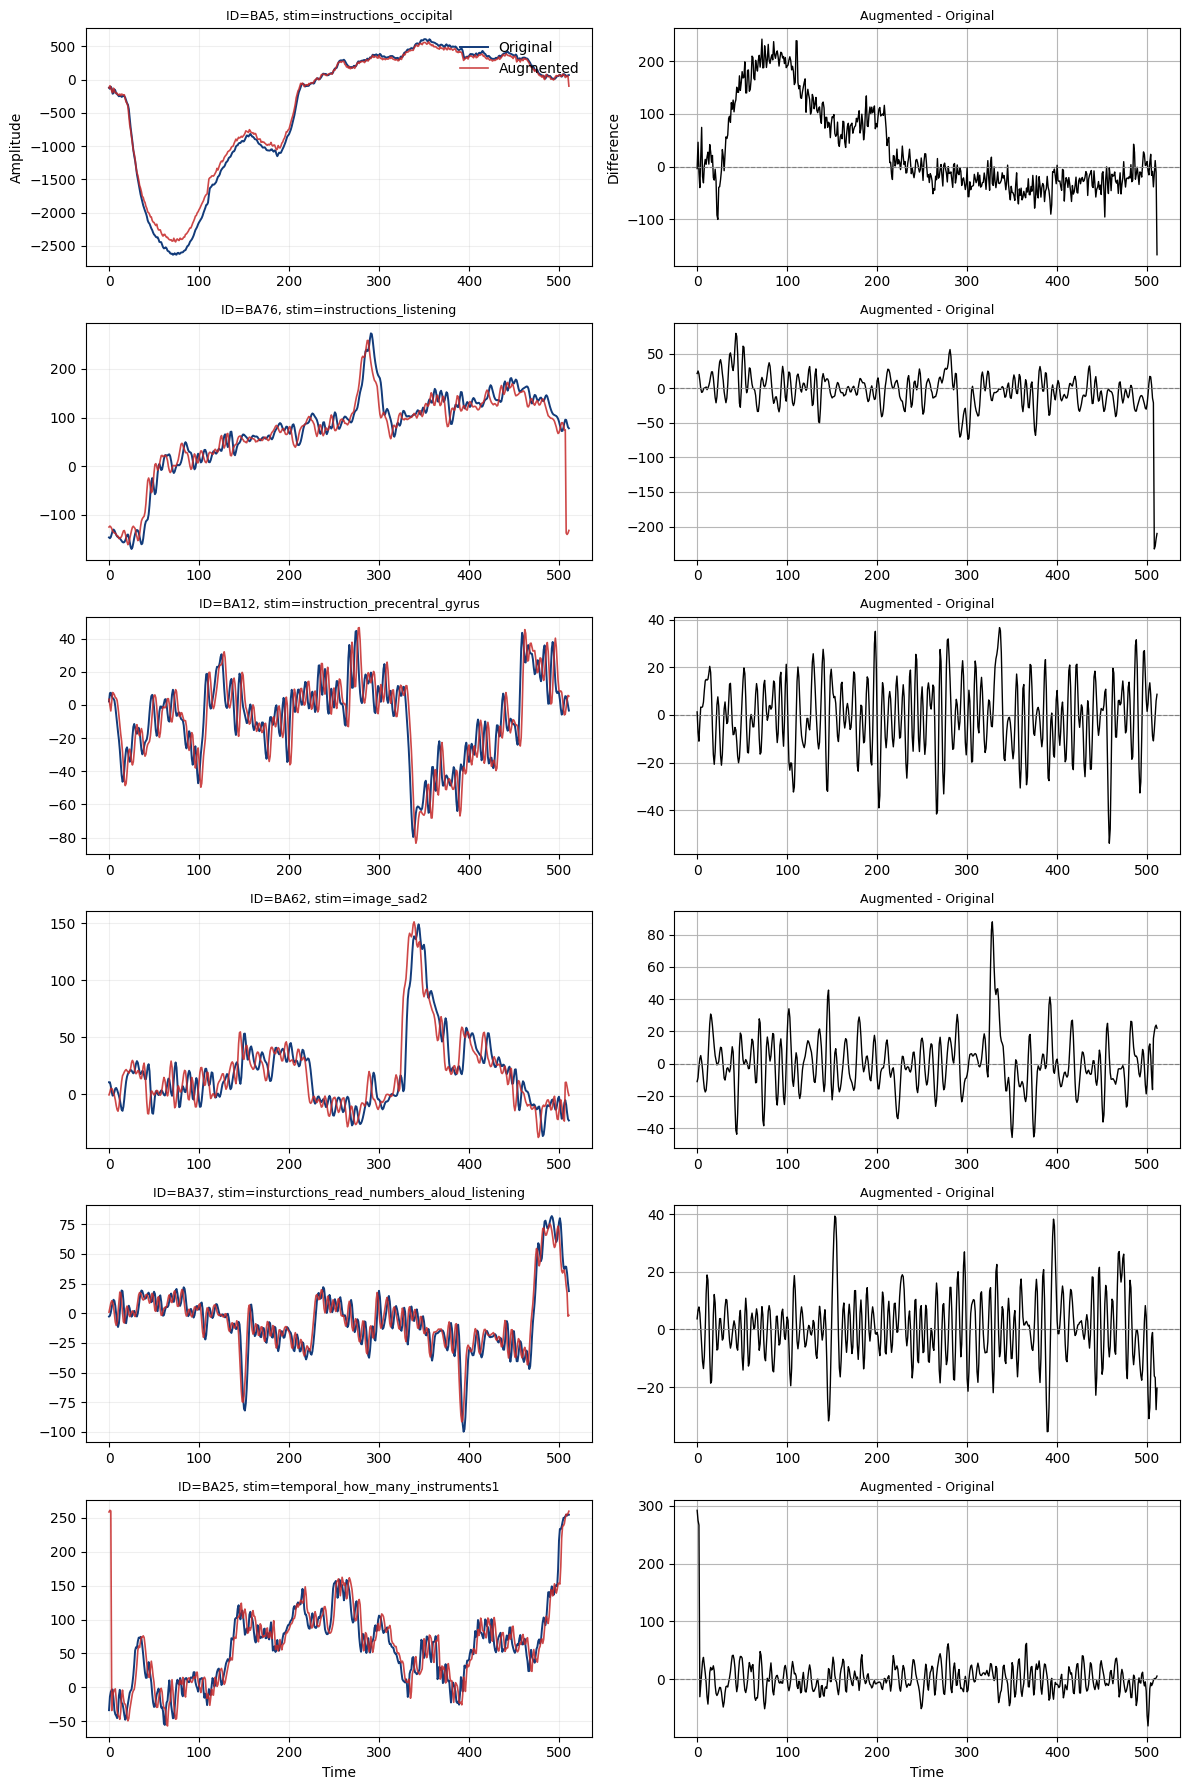

In [38]:
import pickle
import os
from DatasetClasses.DataDrivenContrastiveDataset import EEGContrastivePairs
import torch

'''
    How does Augment work?
'''

import matplotlib.pyplot as plt
import numpy as np



def visualize_augmentation_overlay(dataset, n_samples=5):
    plt.style.use("default")

    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "text.color": "black",
        "axes.labelcolor": "black",
        "xtick.color": "black",
        "ytick.color": "black",
    })
    fig, axes = plt.subplots(
        n_samples, 2,
        figsize=(12, 3 * n_samples),
        sharex=False
    )

    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        # sample one group
        (ID, stim), files = dataset.groups[np.random.randint(len(dataset.groups))]

        f = dataset.rng.choice(files)

        # safer path handling
        if not os.path.exists(f):
            f = os.path.join(dataset.data_dir, os.path.basename(f))

        with open(f, "rb") as fh:
            s = pickle.load(fh)

        x = s["X"][:, dataset.channel_idx].astype(np.float32)

        x_orig = x.copy()
        x_aug = dataset.augment(torch.tensor(x)).numpy()


        diff = x_aug - x_orig

        # common y limits for original/augmented
        ymin = min(x_orig.min(), x_aug.min())
        ymax = max(x_orig.max(), x_aug.max())
        pad = 0.05 * (ymax - ymin + 1e-8)

        # -------------------------------------------------
        # Left: overlay
        # -------------------------------------------------
        ax = axes[i, 0]
        ax.plot(x_orig, color="#123B7A", linewidth=1.4, label="Original")
        ax.plot(x_aug, color="#C62828", linewidth=1.2, alpha=0.85, label="Augmented")
        ax.set_ylim(ymin - pad, ymax + pad)
        ax.set_title(f"ID={ID}, stim={stim}", fontsize=9)
        ax.grid(True, alpha=0.2)

        if i == 0:
            legend = ax.legend(frameon=False, loc="upper right")
            for text in legend.get_texts():
                text.set_color("black")

        # -------------------------------------------------
        # Right: difference
        # -------------------------------------------------
        ax = axes[i, 1]
        ax.plot(diff, color="black", linewidth=1.0)
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title("Augmented - Original", fontsize=9)
        ax.grid(True, alpha=0.9)

    axes[0, 0].set_ylabel("Amplitude")
    axes[0, 1].set_ylabel("Difference")

    axes[-1, 0].set_xlabel("Time")
    axes[-1, 1].set_xlabel("Time")

    plt.tight_layout()
    plt.savefig("MainFigures/augmentation_examples_overlay.pdf", bbox_inches="tight")
    plt.show()
    return fig

dataset = EEGContrastivePairs(
    data_dir="results/EEG_LSTM_windows/",
    channel_idx=0,
    subset_fraction=1.0
)

fig = visualize_augmentation_overlay(dataset, n_samples=6)
plt.close(fig)

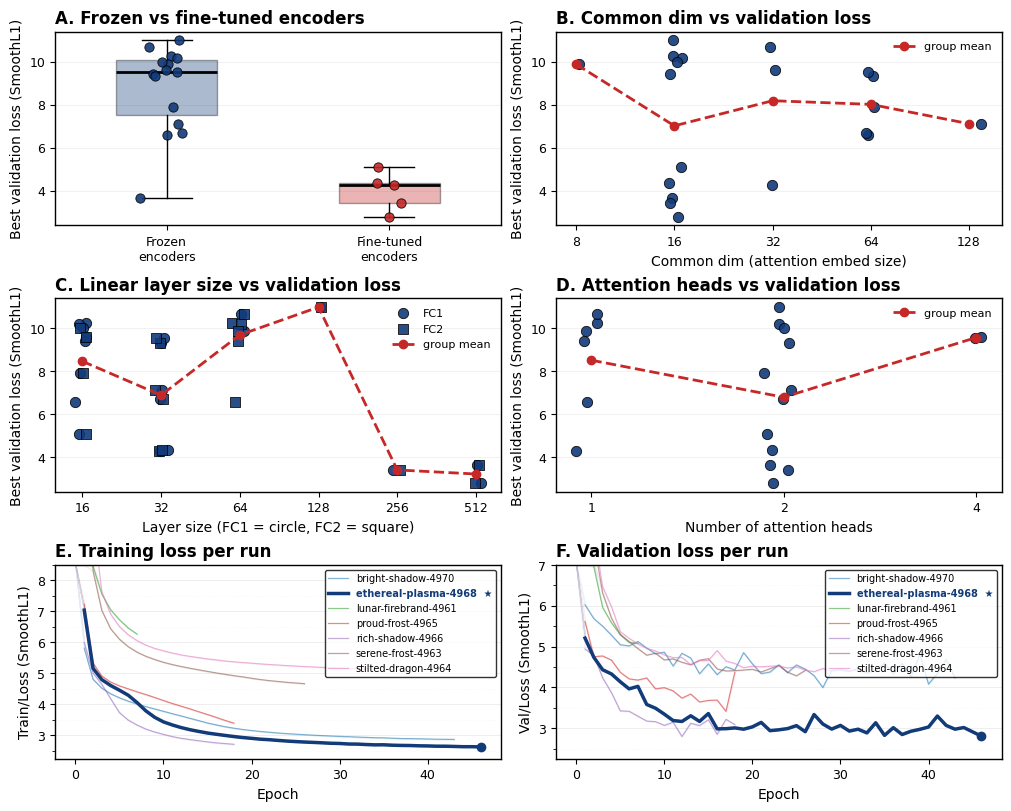

Saved → MainFigures/F5/F5.pdf


In [11]:
'''
FIGURE 5 — Age model hyperparameter sweep + training curves
'''
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

CSV_PATH      = "MainFigures/F5/age_model_runs.csv"
TRAIN_CSV     = "MainFigures/F5/age_model_train.csv"
VAL_CSV       = "MainFigures/F5/age_model_validation.csv"
PDF_PATH      = "MainFigures/F5/F5.pdf"
FOCUS_RUN     = "ethereal-plasma-4968"   # bold + opaque

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=["best_val_loss"]).copy()

plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "font.size":         10,
    "axes.titlesize":    12,
    "axes.labelsize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "text.color":        "black",
    "axes.labelcolor":   "black",
    "axes.edgecolor":    "black",
    "xtick.color":       "black",
    "ytick.color":       "black",
})

blue = "#123B7A"
red  = "#C62828"
gray = "#6E6E6E"

def style_axis(ax):
    ax.tick_params(axis="both", colors="black", labelcolor="black")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)

frozen_df   = df[~df["fine_tune"]].copy()
finetune_df = df[ df["fine_tune"]].copy()
rng = np.random.default_rng(42)

fig, axes = plt.subplots(3, 2, figsize=(10, 8), constrained_layout=True)
axes = axes.flatten()

# ── Panel A: Frozen vs Fine-tuned ─────────────────────────────────────────────
ax = axes[0]
groups = [frozen_df["best_val_loss"].values, finetune_df["best_val_loss"].values]
labels = ["Frozen\nencoders", "Fine-tuned\nencoders"]
colors = [blue, red]

bp = ax.boxplot(groups, patch_artist=True, widths=0.45, tick_labels=labels)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color); patch.set_alpha(0.35); patch.set_edgecolor("black")
for median in bp["medians"]:
    median.set_color("black"); median.set_linewidth(2)
for elem in bp["whiskers"] + bp["caps"]:
    elem.set_color("black")
for i, (vals, color) in enumerate(zip(groups, colors), start=1):
    x_jitter = rng.normal(i, 0.06, size=len(vals))
    ax.scatter(x_jitter, vals, s=45, color=color, edgecolors="black",
               linewidths=0.6, zorder=4, alpha=0.9)

ax.set_title("A. Frozen vs fine-tuned encoders", loc="left", fontweight="bold")
ax.set_ylabel("Best validation loss (SmoothL1)")
ax.grid(True, axis="y", alpha=0.25); ax.set_axisbelow(True)
style_axis(ax)

# ── Shared: scatter + group mean line ────────────────────────────────────────
def scatter_panel(ax, col, title, xlabel, letter, use_log2=True):
    x_raw = df[col].values.astype(float)
    y     = df["best_val_loss"].values.astype(float)
    x     = np.log2(x_raw) if use_log2 else x_raw

    x_jitter = x + rng.normal(0, 0.06 if use_log2 else 0.07, size=len(x))
    ax.scatter(x_jitter, y, s=55, color=blue, edgecolors="black",
               linewidths=0.6, alpha=0.9, zorder=3)

    means = df.groupby(col)["best_val_loss"].mean().reset_index().sort_values(col)
    x_means = np.log2(means[col].values) if use_log2 else means[col].values
    ax.plot(x_means, means["best_val_loss"].values, color=red, linewidth=2,
            linestyle="--", marker="o", markersize=6, zorder=4, label="group mean")

    unique_vals = sorted(df[col].unique())
    ax.set_xticks(np.log2(unique_vals) if use_log2 else unique_vals)
    ax.set_xticklabels([str(int(v)) for v in unique_vals])
    ax.set_title(f"{letter}. {title}", loc="left", fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Best validation loss (SmoothL1)")
    ax.grid(True, axis="y", alpha=0.25); ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8)
    style_axis(ax)

scatter_panel(axes[1], "commonDim", "Common dim vs validation loss",
              "Common dim (attention embed size)", "B")

# ── Panel C: FC1 + FC2 combined ───────────────────────────────────────────────
ax = axes[2]
stacked = pd.concat([
    df[["best_val_loss"]].assign(dim=df["fc1_dim"], layer="FC1"),
    df[["best_val_loss"]].assign(dim=df["fc2_dim"], layer="FC2"),
], ignore_index=True)
for layer, marker in [("FC1", "o"), ("FC2", "s")]:
    sub = stacked[stacked["layer"] == layer]
    x   = np.log2(sub["dim"].values.astype(float))
    x_jitter = x + rng.normal(0, 0.06, size=len(x))
    ax.scatter(x_jitter, sub["best_val_loss"].values,
               s=55, color=blue, edgecolors="black", linewidths=0.6,
               alpha=0.9, marker=marker, zorder=3, label=layer)
means = stacked.groupby("dim")["best_val_loss"].mean().reset_index().sort_values("dim")
x_means = np.log2(means["dim"].values.astype(float))
ax.plot(x_means, means["best_val_loss"].values, color=red, linewidth=2,
        linestyle="--", marker="o", markersize=6, zorder=4, label="group mean")
unique_vals = sorted(stacked["dim"].unique())
ax.set_xticks(np.log2(unique_vals))
ax.set_xticklabels([str(int(v)) for v in unique_vals])
ax.set_title("C. Linear layer size vs validation loss", loc="left", fontweight="bold")
ax.set_xlabel("Layer size (FC1 = circle, FC2 = square)")
ax.set_ylabel("Best validation loss (SmoothL1)")
ax.grid(True, axis="y", alpha=0.25); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8)
style_axis(ax)

scatter_panel(axes[3], "att_heads", "Attention heads vs validation loss",
              "Number of attention heads", "D", use_log2=True)

# ── Helpers for panels E & F ──────────────────────────────────────────────────
def parse_wandb_csv(path, metric_suffix):
    """Return dict: run_name -> (steps, values, mins, maxs)."""
    raw = pd.read_csv(path)
    raw["Step"] = pd.to_numeric(raw["Step"].astype(str).str.strip('"'), errors="coerce")
    raw = raw.dropna(subset=["Step"]).sort_values("Step")
    steps = raw["Step"].to_numpy(dtype=float)

    result = {}
    for col in raw.columns:
        col_clean = col.strip('"')
        if col_clean == "Step" or "__MIN" in col_clean or "__MAX" in col_clean:
            continue
        run = col_clean.replace(f" - {metric_suffix}", "").strip()
        min_col = col + "__MIN"
        max_col = col + "__MAX"
        vals = pd.to_numeric(raw[col].astype(str).str.strip('"'), errors="coerce").to_numpy()
        mins = pd.to_numeric(raw.get(min_col, raw[col]).astype(str).str.strip('"'), errors="coerce").to_numpy()
        maxs = pd.to_numeric(raw.get(max_col, raw[col]).astype(str).str.strip('"'), errors="coerce").to_numpy()
        result[run] = (steps, vals, mins, maxs)
    return result

def plot_training_panel(ax, data_dict, title, ylabel, letter):
    runs = sorted(data_dict.keys())
    cmap = plt.get_cmap("tab10")
    legend_handles = []

    # Compute y-limits from epoch ≥ 1 (skip the large epoch-0 spike)
    all_post_ep0 = []
    for steps, vals, mins, maxs in data_dict.values():
        mask = (steps >= 1) & ~np.isnan(vals)
        all_post_ep0.extend(vals[mask].tolist())
    all_post_ep0 = np.array(all_post_ep0)
    y_lo = np.floor(all_post_ep0.min() * 2) / 2 - 0.25          # round down to 0.5
    y_hi = np.ceil(np.percentile(all_post_ep0, 95) * 2) / 2 + 1  # p95 + 1 unit headroom

    for i, run in enumerate(runs):
        steps, vals, mins, maxs = data_dict[run]
        is_focus = (run == FOCUS_RUN)

        color  = blue if is_focus else cmap(i % 10)
        lw     = 2.5  if is_focus else 0.9
        alpha  = 1.0  if is_focus else 0.55
        zorder = 5    if is_focus else 2
        label  = f"{run}  ★" if is_focus else run

        # shaded min/max band, clipped to visible range
        mask = ~(np.isnan(mins) | np.isnan(maxs))
        if mask.any():
            ax.fill_between(steps[mask],
                            np.clip(mins[mask], y_lo, y_hi),
                            np.clip(maxs[mask], y_lo, y_hi),
                            alpha=0.18 if is_focus else 0.08,
                            color=color)

        # clip values so out-of-range epochs don't stretch the axis
        vals_clipped = np.where((steps >= 1), vals, np.nan)
        line, = ax.plot(steps, vals_clipped, linewidth=lw, alpha=alpha,
                        color=color, zorder=zorder, label=label)

        if is_focus:
            last_valid = vals[~np.isnan(vals)]
            if len(last_valid):
                ax.plot(steps[~np.isnan(vals)][-1], last_valid[-1],
                        "o", color=blue, markersize=6, zorder=6)

        legend_handles.append(line)

    ax.set_ylim(y_lo, y_hi)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1.0))   # tick every 1 unit
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))   # minor every 0.5
    ax.grid(True, which="major", axis="y", alpha=0.30)
    ax.grid(True, which="minor", axis="y", alpha=0.12, linestyle=":")

    ax.set_title(f"{letter}. {title}", loc="left", fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)

    leg = ax.legend(handles=legend_handles,
                    labels=[h.get_label() for h in legend_handles],
                    frameon=True, fontsize=7, loc="upper right",
                    facecolor="white", edgecolor="black")
    for text in leg.get_texts():
        if FOCUS_RUN in text.get_text():
            text.set_fontweight("bold")
            text.set_color(blue)

    style_axis(ax)

# ── Panel E: Train/Loss ────────────────────────────────────────────────────────
train_data = parse_wandb_csv(TRAIN_CSV, "Train/Loss")
plot_training_panel(axes[4], train_data,
                    "Training loss per run", "Train/Loss (SmoothL1)", "E")

# ── Panel F: Val/Loss ──────────────────────────────────────────────────────────
val_data = parse_wandb_csv(VAL_CSV, "Val/Loss")
plot_training_panel(axes[5], val_data,
                    "Validation loss per run", "Val/Loss (SmoothL1)", "F")



fig.savefig("{}.png".format(PDF_PATH), bbox_inches="tight", facecolor="white")
fig.savefig("{}.png".format(PDF_PATH), bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)
print(f"Saved → {PDF_PATH}")
